# Task 2

### Setup

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd

SEED = 22040 # Fixed number for the RNG to ensure reproducability.
random.seed(SEED)
np.random.seed(SEED)

### Functions from Task 1

In [2]:
# Parent Selection Function: 
# (Inputs: Individuals, Fitness values;
# Output: Parents (in random order, same number as individuals)). 
def parent_selection( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional parent selection such that more fit parents have a higher probability to be selected. """
    fitness = np.array(fitness_values, dtype=float)
    probs = fitness / fitness.sum()
    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]


# Recombination (Crossover) Function:
# (Inputs: Parents, Crossover Probability;
# Outputs: Offspring (pre-Mutation)). 
def one_point_crossover( parents: list[list[int]], crossover_prob: float ) -> list[list[int]]:
    """Performs 1-point crossover and generates for parents 1 & 2, parents 3 & 4 etc. offspring. """
    offsprings = []
    for i in range(0, len(parents)-1, 2):
        parent1, parent2 = parents[i], parents[i+1]
        offspring1, offspring2 = parent1.copy(), parent2.copy()

        alpha = np.random.uniform(0, 1)
        if alpha <= crossover_prob:
            cpoint = random.randint(1, len(parent1) - 1)
            offspring1 = parent1[:cpoint] + parent2[cpoint:]
            offspring2 = parent2[:cpoint] + parent1[cpoint:]

        offsprings.append(offspring1)
        offsprings.append(offspring2)

    if len(parents) % 2 == 1:
        offsprings.append(parents[-1].copy())

    return offsprings


# Mutation Function:
# (Inputs: Individuals, Mutation Probability $P_M$;
#  Outputs: Offspring (mutated)). 
def mutation( individuals: list[list[int]], mutation_prob: float ) -> list[list[int]]:
    """Performs bitflip mutation for each bit / gene in each individual with mutation probability of P_M."""
    mutated = []
    for individual in individuals:
        offspring = individual.copy()
        for i in range(len(offspring)):
            if np.random.uniform(0, 1) <= mutation_prob:
                offspring[i] = 1 - individual[i] # flipping each bit
            else:
                continue
        mutated.append(offspring)
    return mutated


# Survivor Selection Function:
# (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring;
# Outputs: (New) population). 
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]] 

## Subtask 1
Load the data set data 1001.csv. The first column contains the values for
each item - save them as a list item values - and the second column con-
tains the weights of each item - save them as a list item weights. State the
size of the data set and analyze the values and the weights that the items
take and any possible relationship between the values and the weights.
Comment on your findings.

**Note on outlier:** (value: *3300*, weight: *100000*) is an extreme outlier. Its weight is roughly 5× larger than any other item and it lies far from the linear value-weight trend followed by the rest of the data. To keep the plots readable, it is excluded from the **scatter plot** and **histograms** below; summary statistics are reported with the outlier. The item is **kept in the data set for the GA**, since it is a valid item in the knapsack problem.

### Analyzing data

#### Reading data
**NOTE:** also setting up data_31 for testing

In [3]:
df = pd.read_csv('../data/data_1001.csv')

item_values = df["Value"].to_list()
item_weights = df["Weight"].to_list()

# without the outlier
df_no_outlier = df[df["Weight"] <= 50000]
item_values_no_outlier = df_no_outlier["Value"].to_list()
item_weights_no_outlier = df_no_outlier["Weight"].to_list()


test_df = pd.read_csv('../data/data_31.csv')
test_item_values = test_df["Value"].to_list()
test_item_weights = test_df["Weight"].to_list()


#### lenght of data

In [4]:
print("Lenght with all entries")
print(f"Length of item_values: {len(item_values)}")
print(f"Length of item_weights: {len(item_weights)}")

print("\nLenght without outlier")
print(f"Length of item_values_no_outlier: {len(item_values_no_outlier)}")
print(f"Length of item_weights_no_outlier: {len(item_weights_no_outlier)}")

Lenght with all entries
Length of item_values: 1001
Length of item_weights: 1001

Lenght without outlier
Length of item_values_no_outlier: 1000
Length of item_weights_no_outlier: 1000


#### Describing the data (value and weight)

In [5]:
print(df.describe())

              Value         Weight
count   1001.000000    1001.000000
mean    5762.173826   10134.013986
std     5770.419772    6386.142389
min    -4299.000000       1.000000
25%      940.000000    5245.000000
50%     5819.000000   10133.000000
75%    10596.000000   15012.000000
max    17195.000000  100000.000000


#### Distribution of item_values

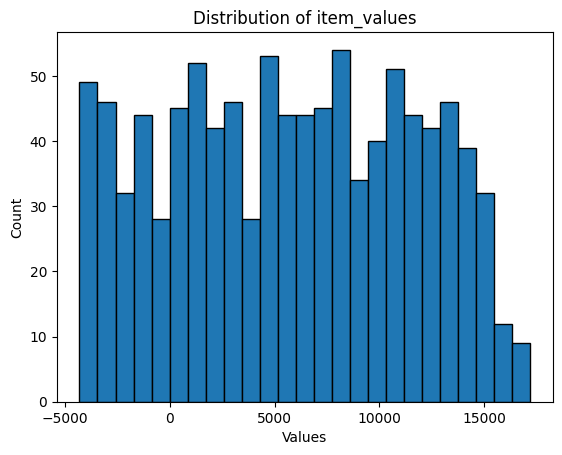

In [6]:
plt.hist(item_values, bins=25, edgecolor='black')
plt.xlabel('Values')
plt.ylabel('Count')
plt.title('Distribution of item_values')
plt.show()

#### Distribution of item_weights

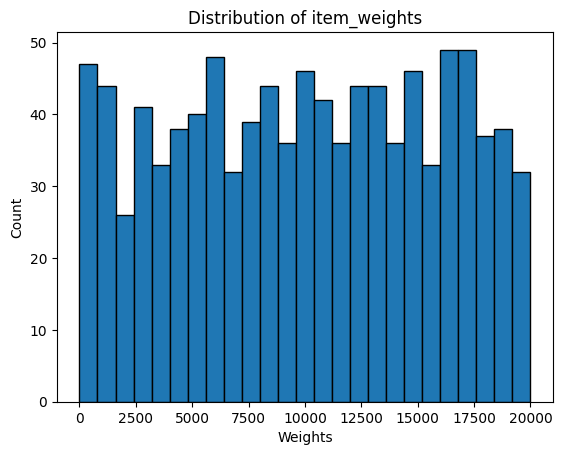

In [7]:
plt.hist(item_weights_no_outlier, bins=25, edgecolor='black')
#plt.xlim(right=30000)
plt.xlabel('Weights')
plt.ylabel('Count')
plt.title('Distribution of item_weights')
plt.show()

#### Scatter plot of value against weight.

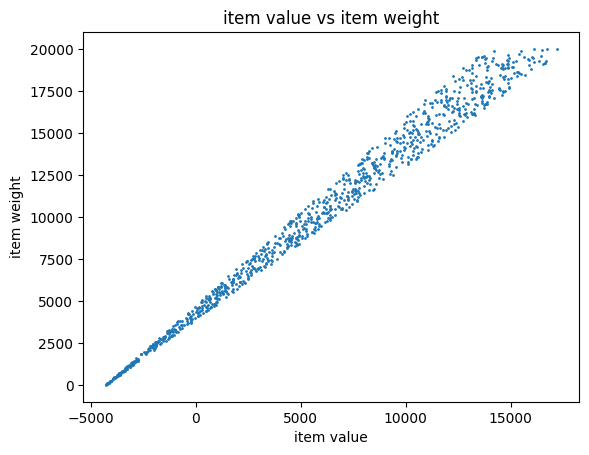

In [8]:
plt.scatter(item_values_no_outlier, item_weights_no_outlier, s=1)
plt.xlabel('item value')
plt.ylabel('item weight')
plt.title('item value vs item weight')
plt.show()


#### Maximum fitness
Summing the value of all items, where value >= 0

In [21]:
postive_values_only = df[df["Value"] >= 0]


print("Number of items, where value >= 0", postive_values_only.shape[0])

sum_of_values = postive_values_only.Value.sum()

print("Maximum fitness (only postive items): ", sum_of_values)

print("Sum of fitness (all items): ", df.Value.sum())

Number of items, where value >= 0 802
Maximum fitness (only postive items):  6231819
Sum of fitness (all items):  5767936


#### Correlation matrix

In [10]:
matrix = df.corr(numeric_only=True)
print(matrix)

           Value    Weight
Value   1.000000  0.883573
Weight  0.883573  1.000000


### What can we extract from the information above?

**Dataset size:** the data set contains 1001 items, each with a value and weight.

**Value and weight distributions:** Item values range from -4299 to 17,195 (mean = 5762), and weights range from 1 to 100,000 (mean = 10134). Notably, some item values are negative.

**Outlier:** item with (value: [3300], weight: [100,000]) is an extreme outlier, with a weight far above all other items and well off the trend followed by the rest of the data. It is excluded from the plots for readability but kept in the data set for the GA.

**Relationship between the values and weights:** The scatter plot shows a strong linear relationship: heavier items tend to be more valuable. We can also see this in the correlation matrix.

**Values being able to be negative:** another interesting thing to keep in mind, after looking at the data is that item values can be negative (ranging from -4299 to 17195).

**Maximum possible fitness:** Since Task 2 has no weight limit, the optimal solution is to select all items with positive values and exclude all other. So we can find the maximum possible fitness by summing the value of all items with positive values, that turns out to be **maximum possible fitness = 6231819**. This lets us measure how close the GA gets to the true optimum.

**Effect of negative values on selection:** the problem that may come up is that if an individuals fitness is negative that breaks *np.random.choice*. But for the most part we should be safe since the mean item value is around 5762.

## Subtask 2
Write a NEW initialization function that creates a binary list that is
suitable to represent this problem. As before: (Inputs: Population Size,
Output: Individuals).

In [11]:
# import variables
# item_values: list of all values
# item_weights: list of all weights

def initialization_knapsack( pop_size: int, num_bits: int  ) -> list[list[int]]:
    """
    This function creates the individuals for the population, each having num_bits genes. 

    Returns:
      A list of `pop_size` individuals, each a list of `num_bits` ints (0 or 1).
    
    Example:
        >>> initialization_knapsack(pop_size=3, num_bits=4)
        [[0, 1, 1, 0], [1, 0, 0, 1], [1, 1, 0, 0]]
    """
    population = []
    for _ in range(pop_size):
        population.append(np.random.randint(0, 2, num_bits, int).tolist())
    return population

#### Testing subtask 2

In [12]:
def test_initialization_knapsack():
    population_size = 5
    gene_len        = len(item_values)

    population = initialization_knapsack(
        pop_size=population_size,
        num_bits=gene_len)

    print("Testing population size: expected 5")
    if len(population) == 5:
        print("CORRECT")
        print("population size: ", len(population))
    else:
        print("INCORRECT")

    print()

    print("Testing individual lenght: expected 1001")
    individual_1 = population[0]
    if len(individual_1) == 1001:
        print("CORRECT")
        print("individual size: ", len(individual_1))
    else:
        print("INCORRECT")
        print("individual size: ", len(individual_1))

    print()

    print("Printing Individuals")
    print(f"num{"":>5}| {"0 count":<} | {"1 count":<} | only (1/0) | {"First 20 of gene":<30} | ")
    for num, ind in enumerate(population):
        ones  = ind.count(1)
        zeros = ind.count(0)
        only_binary = (ones + zeros == len(ind))
        print(f"{num+1:<8}| {zeros:<7} | {ones:<7} | {only_binary:<10} | {ind[:10]} | ")
    
    print()
    all_binary = all(ind.count(0) + ind.count(1) == len(ind) for ind in population)
    print(f"All individuals contain only 0s and 1s: {all_binary}")

test_initialization_knapsack()

Testing population size: expected 5
CORRECT
population size:  5

Testing individual lenght: expected 1001
CORRECT
individual size:  1001

Printing Individuals
num     | 0 count | 1 count | only (1/0) | First 20 of gene               | 
1       | 507     | 494     | 1          | [1, 0, 0, 1, 0, 0, 1, 0, 1, 0] | 
2       | 517     | 484     | 1          | [0, 1, 1, 0, 0, 0, 0, 0, 1, 1] | 
3       | 504     | 497     | 1          | [1, 0, 0, 0, 1, 1, 1, 0, 1, 1] | 
4       | 532     | 469     | 1          | [1, 0, 0, 1, 0, 0, 0, 1, 1, 1] | 
5       | 462     | 539     | 1          | [0, 1, 0, 0, 1, 0, 0, 0, 1, 0] | 

All individuals contain only 0s and 1s: True


## Subtask 3
Since the aim of knapsack is to maximize the value of items selected (0 -
not selected, 1 - selected), write a NEW fitness function that sums the
value of all items selected.

**NOTE:** The fitness function ignores weight completly

In [13]:
# using dotproduct to find fitness
def fitness (individuals: list[list[int]], values: list[int]) -> list[int]:
    """
    Calculate the fitness of each individual in the population.

    An individual's fitness is the total value of the items it selects,
    computed as the dot product of its genes and the item values.

    Args:
        individuals: list of individuals in the population
        values: list of item values
    
    Returns:
        A list with one fitness score per individual.
    
    Example:
        >>> fitness([[0,1,1],[1,1,0]], [200,100,50])
        [150, 300]
    """
    #value_list = [None] * len(individuals)

    #for index in range(len(individuals)):
    #    value_list[index] = np.dot(individuals[index], values)
    
    #return value_list

    return (np.array(individuals) @ np.array(values)).tolist()

#### Testing fitness function

In [14]:
def test_fitness():
    pop_size = 5
    gene_len = len(test_item_values)

    population = initialization_knapsack(pop_size, gene_len)
    fitness_values = fitness(population, test_item_values)
    
    print(f"Individual{"":<1} | Fitness{"":<7} |")
    for index in range(len(population)):
        print("-" * 12 + "|" + "-" * 16 + "|")
        print(f"{index:<11} | {fitness_values[index]:<15}|")


    sum_first_3 = sum(test_item_values[:3])
    test_1 = [0] * gene_len
    test_1[:3] = [1, 1, 1] 
    test_1_fit = fitness([test_1], test_item_values)

    print(sum_first_3)
    print("Gene with first 3 bits on")
    print(f"Correct : {sum_first_3}")
    print(f"fitness : {test_1_fit[0]}")

    all_zero = 0
    test_2 = [0] * gene_len
    test_2_fit = fitness([test_2], test_item_values)

    print(sum_first_3)
    print("Gene with all bits set to zero")
    print(f"Correct : {all_zero}")
    print(f"fitness : {test_2_fit[0]}")
    

test_fitness()    

Individual  | Fitness        |
------------|----------------|
0           | 689069         |
------------|----------------|
1           | 695576         |
------------|----------------|
2           | 686777         |
------------|----------------|
3           | 539058         |
------------|----------------|
4           | 693811         |
156780
Gene with first 3 bits on
Correct : 156780
fitness : 156780
156780
Gene with all bits set to zero
Correct : 0
fitness : 0


## Subtask4
Run the SGA with the new initialization and new fitness function, with
population size 30, number of iterations 1000, PC = 0.9 and PM = 0.1.
State the average fitness of the final population and the best fitness in the
final population. (Note: Since the SGA is heuristic, different groups may
end up with different best solutions and best fitness values).

In [ ]:
def simple_genetic_algorithm(
    population_size, number_iter,
    crossover_prob, mutation_prob,
    value_list
    ) -> tuple[list[float], list[float], list[list[int], list[float]]]:
    """
    SGA for Task 2

    Returns:
        A list with 4 items.
        * avg_fitness_data
        * best_fitness_data
        * population
        * fitness_values
    """
    # To keep track of avg and best fitness across iterations
    avg_fitness_data, best_fitness_data = [], []
    # curr_avg_fit, curr_best_fit = 0.0, 0.0
    
    gene_len = len(value_list)
    population = initialization_knapsack(
        pop_size=population_size,
        num_bits=gene_len
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, value_list)

        new_avg_fitness = np.mean(fitness_values)
        avg_fitness_data.append(new_avg_fitness)

        new_best_fitness = np.max(fitness_values)
        best_fitness_data.append(new_best_fitness)

        # if new_best_fitness > curr_best_fit:
        #    curr_best_fit = new_best_fitness

        parents = parent_selection(population, fitness_values)

        offspring = one_point_crossover(parents, crossover_prob)
        offspring = mutation(offspring, mutation_prob)
        offspring_fitness_values = fitness(offspring, value_list)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return avg_fitness_data, best_fitness_data, population, fitness(population, value_list)

### Testing SGA

Average fitness of final population: 4172093.8666666667
Best fitness of final population: 4254065


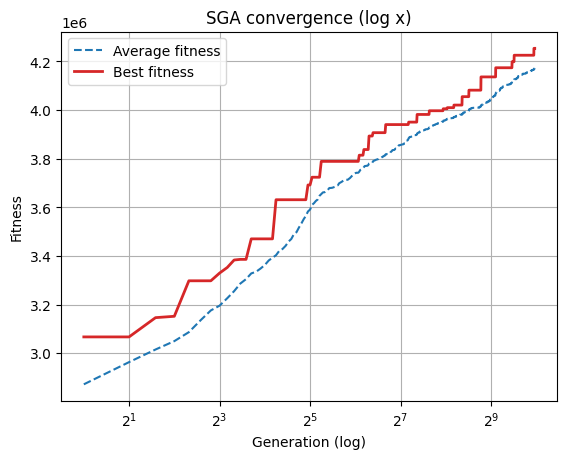

In [16]:
def plot_fitness_data( avg_fitness_data: list[float], best_fitness_data: list[float], num_iter: int ):
    gens = range(1, num_iter + 1)

    plt.plot(gens, avg_fitness_data, color="tab:blue", linestyle="--", label="Average fitness")
    plt.plot(gens, best_fitness_data, color="tab:red",  linestyle="-",  linewidth=2, label="Best fitness")
    plt.xscale("log", base=2)
    plt.xlabel("Generation (log)")
    plt.ylabel("Fitness")
    plt.title("SGA convergence (log x)")
    plt.legend()
    plt.grid(True)
    plt.show()


def test_SGA(
    pop_size            = 10,
    number_iternations  = 100,
    crossover_prob      = 0.9,
    mutation_prob       = 0.1,
    value_list          = None):
    """
    Test SGA
    """
    if value_list is None:
        print("value_list missing")
        return None
    
    report = simple_genetic_algorithm(
        pop_size,
        number_iternations,
        crossover_prob,
        mutation_prob,
        value_list
    )
    avg_fitness_data   = report[0]
    best_fitness_data  = report[1]
    population         = report[2]
    population_fitness = report[3]

    print(f"Average fitness of final population: {np.mean(population_fitness)}")
    print(f"Best fitness of final population: {np.max(population_fitness)}")

    plot_fitness_data( avg_fitness_data, best_fitness_data, number_iternations)
    
    return report

# test with data_31.csv
#test_SGA(30, 1000, 0.9, 0.1, test_item_values)

# test with data_1001.csv
report = test_SGA(30, 1000, 0.9, 0.1, item_values)
avg_fitness_data   = report[0]
best_fitness_data  = report[1]
population         = report[2]
population_fitness = report[3]

## SubTask 5
The best solution found is harder to interpret than before (as it cannot
just be converted into a single integer). Thus, describe the solution found
based on the fitness, number of items selected, and the min, mean, max of
the values, of the weights and of the ratio of value-to-weight of the selected
items. Compare this with the same information on the items that were
not selected. Comment on your findings and whether the results are as
expected. Why / why not?

### Code

In [17]:
OPTIMUM = 6231819


best_index      = np.argmax(population_fitness)
best_individual = np.array(population[best_index])
best_fitness    = population_fitness[best_index]

print(f"Best fitness: {best_fitness}")
print(f"Percentage of optimum: {best_fitness / OPTIMUM * 100:.2f}%")

values  = np.array(item_values)
weights = np.array(item_weights)
ratios  = values / weights

selected = best_individual == 1

sel_values,   unsel_values   = values[selected],  values[~selected]
sel_weights,  unsel_weights  = weights[selected], weights[~selected]
sel_ratios,   unsel_ratios   = ratios[selected],  ratios[~selected]

def describe_group(vals, wts, rts):
    return {
        "Number of items": len(vals),
        "Value min":  vals.min(),  "Value mean":  vals.mean(),  "Value max":  vals.max(),
        "Weight min": wts.min(),   "Weight mean": wts.mean(),   "Weight max": wts.max(),
        "Ratio min":  rts.min(),   "Ratio mean":  rts.mean(),   "Ratio max":  rts.max(),
    }

comparison = pd.DataFrame({
    "Selected":     describe_group(sel_values,   sel_weights,   sel_ratios),
    "Not selected": describe_group(unsel_values, unsel_weights, unsel_ratios),
})

print(comparison.round(2))

positive = values > 0

print(f"Positive-value items selected: {(selected & positive).sum()} of {positive.sum()}")
print(f"Negative-value items selected: {(selected & ~positive).sum()} of {(~positive).sum()}")

Best fitness: 4254065
Percentage of optimum: 68.26%
                  Selected  Not selected
Number of items     614.00        387.00
Value min         -4227.00      -4299.00
Value mean         6928.44       3911.81
Value max         17195.00      16648.00
Weight min           73.00          1.00
Weight mean       11353.31       8199.53
Weight max       100000.00      19677.00
Ratio min           -57.90      -4299.00
Ratio mean           -0.04        -12.61
Ratio max             0.87          0.87
Positive-value items selected: 534 of 802
Negative-value items selected: 80 of 199


### Writen part

#### Description of the best solution
**Results from Model**
The best solution has a fitness of **4,254,065**, which is **68.26%** of the maximum possible fitness (6,231,819). It selects **614** of the 1001 items.

```text
Best fitness: 4254065
Percentage of optimum: 68.26%
                  Selected  Not selected
Number of items     614.00        387.00
Value min         -4227.00      -4299.00
Value mean         6928.44       3911.81
Value max         17195.00      16648.00
Weight min           73.00          1.00
Weight mean       11353.31       8199.53
Weight max       100000.00      19677.00
Ratio min           -57.90      -4299.00
Ratio mean           -0.04        -12.61
Ratio max             0.87          0.87
Positive-value items selected: 534 of 802
Negative-value items selected: 80 of 199
```

The optimal solution would select all 802 positive-value items and none of the 199 negative-value items. Our solution selects **534 of the 802** positive items (67%) and **80 of the 199** negative items (40%).

**Values:** The selected items have a clearly higher mean value than the unselected ones (6,928 vs. 3,912), so the SGA has moved in the right direction: a random individual selects about half of each group, while our solution includes more positive and fewer negative items than that. However, the solution is far from optimal: it still contains 80 negative-value items and misses 268 positive-value items, including some very valuable ones (the unselected maximum is 16,648).

**Value-to-weight ratio:** The ratio is not optimized, since weight plays no role in the fitness function, and both groups contain the same maximum ratio (0.87). The mean ratios are dominated by negative-value items with very small weights (e.g. value -4,299 with weight 1 gives a ratio of −4,299), so they say little about the typical item. A median would describe the groups better.

**Are the results as expected?** Partly. We expected the selected items to have higher values, and their higher weights are explained by the value–weight correlation. Not reaching the optimum is also expected given the settings:
* **Mutation is very disruptive:** with PM = 0.1 and 1001 genes, about 100 bits are flipped in each child, so a good solution is likely to be damaged by mutation.
* **Weak selection pressure:** all individuals contain hundreds of items, so their fitness values are large and close together, and fitness-proportional selection barely favours the best individuals.
* **Progress comes mainly from survivor selection:** the deterministic survivor selection keeps the best individuals, so fitness never decreases, but improvement is slow because most offspring are worse than their parents.

A lower mutation rate (e.g. PM = 1/1001) would likely bring the solution much closer to the optimum.